# Task 2 — Data Cleaning & Return Engineering
### QFI Internship · Market Risk Project · Phase 2
**Prepared by:** Arham Shah

---

**Objective.** Turn the raw prices from Task 1 into analysis-ready return data, logging every cleaning decision so the results can be audited.

**What this notebook delivers**
- Calendar alignment and **gap-limited** forward filling (so long outages are never silently filled)
- Stale-price detection using **run lengths**, not just repeated-price counts
- **Robust (MAD) outlier detection** with a data-driven keep-or-clip decision, and its effect on VaR
- Simple **and** log returns, with the portfolio aggregated the correct way
- Three volatility estimators: 21-day, 63-day rolling and **EWMA (RiskMetrics λ = 0.94)**
- Distribution diagnostics (skew, kurtosis, Jarque–Bera) and a correlation heatmap
- A saved **cleaning audit log**

> **Pipeline:** Task 1 (Collection) → **Task 2 (Cleaning)** → Task 3 (Construction) → VaR / Backtesting

> **How to run:** open in Google Colab → *Runtime → Run all*. The notebook downloads anything it needs, so it also works if run on its own.

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings('ignore')

try:
    import yfinance as yf
except ImportError:            # Colab usually has it; install if missing
    %pip install -q yfinance
    import yfinance as yf

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

plt.rcParams.update({
    'figure.figsize': (12, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


In [2]:
# ---- Project configuration (single source of truth) ----------------------
UNIVERSE = {                     # ticker : GICS-style sector
    'AAPL' : 'Information Technology',
    'MSFT' : 'Information Technology',
    'NVDA' : 'Information Technology',
    'GOOGL': 'Communication Services',
    'META' : 'Communication Services',
    'AMZN' : 'Consumer Discretionary',
    'TSLA' : 'Consumer Discretionary',
    'JPM'  : 'Financials',
    'XOM'  : 'Energy',
    'UNH'  : 'Health Care',
}
TICKERS    = list(UNIVERSE)
BENCHMARK  = '^GSPC'             # S&P 500
START_DATE = '2020-07-24'
END_DATE   = '2026-07-25'        # yfinance end date is exclusive
TRADING_DAYS = 252

RAW_PRICE_FILE  = 'Raw_Portfolio_Price.csv'
RAW_VOLUME_FILE = 'Raw_Portfolio_Volume.csv'
BENCH_FILE      = 'Benchmark_prices.csv'

print(f'{len(TICKERS)} stocks across {len(set(UNIVERSE.values()))} sectors | '
      f'benchmark {BENCHMARK} | {START_DATE} -> {END_DATE}')

# Cleaning parameters
FFILL_LIMIT     = 3      # max consecutive days we are willing to carry a price forward
STALE_THRESHOLD = 5      # flag runs of >= N identical closes (a frozen trading week)
MAD_Z_THRESHOLD = 8.0    # robust z-score above which a return is investigated
WINSORIZE       = False  # see Section 5 for why the default is OFF
EWMA_LAMBDA     = 0.94   # RiskMetrics daily decay factor

10 stocks across 6 sectors | benchmark ^GSPC | 2020-07-24 -> 2026-07-25


## 1. Load raw data
Uses Task 1's CSVs if they exist in this session, and otherwise re-downloads them automatically.

In [3]:
# ---- Robust Yahoo Finance downloader (retries + clear errors) ------------
def download_yahoo(symbols, start, end, retries=3, pause=2):
    """Return (adj_close, volume) DataFrames for `symbols`."""
    symbols = [symbols] if isinstance(symbols, str) else list(symbols)
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            raw = yf.download(symbols, start=start, end=end, auto_adjust=False,
                              progress=False, threads=True, group_by='column')
            adj, vol = raw['Adj Close'], raw['Volume']
            if isinstance(adj, pd.Series):
                adj, vol = adj.to_frame(symbols[0]), vol.to_frame(symbols[0])
            adj, vol = adj[symbols].dropna(how='all'), vol[symbols].reindex(adj.dropna(how='all').index)
            if not adj.empty:
                return adj, vol
            last_err = 'empty response'
        except Exception as e:
            last_err = e
        print(f'  attempt {attempt}/{retries} failed ({last_err}); retrying...')
        time.sleep(pause * attempt)
    raise RuntimeError(f'Yahoo download failed for {symbols}: {last_err}')

In [4]:
# ---- Load Task 1 output, or rebuild it if this runs in a fresh session -----
if os.path.exists(RAW_PRICE_FILE) and os.path.exists(BENCH_FILE):
    prices_raw = pd.read_csv(RAW_PRICE_FILE, index_col=0, parse_dates=True)
    benchmark  = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True).iloc[:, 0]
    source = 'Task 1 CSV files'
else:
    prices_raw, _ = download_yahoo(TICKERS, START_DATE, END_DATE)
    bench_df, _   = download_yahoo(BENCHMARK, START_DATE, END_DATE)
    benchmark     = bench_df.iloc[:, 0]
    prices_raw.to_csv(RAW_PRICE_FILE); benchmark.to_frame('S&P 500').to_csv(BENCH_FILE)
    source = 'fresh Yahoo Finance download (Task 1 files not found)'

prices_raw.index.name = benchmark.index.name = 'Date'
benchmark.name = 'S&P 500'
prices_raw = prices_raw[TICKERS]
print(f'Source: {source}')
print(f'Prices: {prices_raw.shape[0]} rows x {prices_raw.shape[1]} stocks | benchmark: {len(benchmark)} rows')

Source: Task 1 CSV files
Prices: 1507 rows x 10 stocks | benchmark: 1507 rows


In [5]:
audit = []          # every cleaning action is appended here
def log(step, detail, n_affected=0):
    audit.append({'Step': step, 'Detail': detail, 'Observations affected': int(n_affected)})
    print(f'[{step}] {detail} ({n_affected})')

## 2. Align trading dates
The benchmark calendar defines the official set of market days. We also sort the index and remove duplicate dates.

In [6]:
n0 = len(prices_raw)
prices = prices_raw[~prices_raw.index.duplicated(keep='last')].sort_index()
log('Calendar', 'Duplicate dates removed', n0 - len(prices))

benchmark = benchmark[~benchmark.index.duplicated(keep='last')].sort_index().dropna()
extra = prices.index.difference(benchmark.index)
prices = prices.reindex(benchmark.index)
log('Calendar', 'Stock dates not on benchmark calendar dropped', len(extra))
print('Index equals benchmark calendar:', prices.index.equals(benchmark.index))

[Calendar] Duplicate dates removed (0)
[Calendar] Stock dates not on benchmark calendar dropped (0)
Index equals benchmark calendar: True


## 3. Missing values: forward fill with a limit
Carrying yesterday's price forward is fine for a one-day glitch. Filling a two-week outage would invent a flat, zero-volatility period, so the fill is capped at `FFILL_LIMIT` days and anything longer is reported rather than hidden.

In [7]:
na_before = prices.isna()
prices_clean = prices.ffill(limit=FFILL_LIMIT)
filled = int((na_before & prices_clean.notna()).sum().sum())
log('Missing', f'Gaps forward-filled (limit {FFILL_LIMIT} days)', filled)

unfilled_inside = prices_clean.loc[prices_clean.first_valid_index():].isna().sum()
if unfilled_inside.sum():
    print('WARNING - gaps longer than limit remain:\n', unfilled_inside[unfilled_inside > 0])
n_rows = len(prices_clean)
prices_clean = prices_clean.dropna(how='any')
log('Missing', 'Rows dropped with remaining NaNs (leading / long gaps)', n_rows - len(prices_clean))
benchmark = benchmark.reindex(prices_clean.index)
print(f'Clean price matrix: {prices_clean.shape[0]} days x {prices_clean.shape[1]} stocks, '
      f'NaNs left = {int(prices_clean.isna().sum().sum())}')

[Missing] Gaps forward-filled (limit 3 days) (0)
[Missing] Rows dropped with remaining NaNs (leading / long gaps) (0)
Clean price matrix: 1507 days x 10 stocks, NaNs left = 0


## 4. Stale-price detection (run-length based)
Counting how often a price equals the previous day's price is a weak test, since a stock can close flat. A **run** of several identical closes in a row is the real warning sign of a frozen feed.

In [8]:
def stale_runs(s, min_len):
    same = s.eq(s.shift())
    grp = (~same).cumsum()
    runs = same.groupby(grp).agg(['sum'])
    runs['start'] = s.groupby(grp).apply(lambda x: x.index[0])
    runs = runs[runs['sum'] + 1 >= min_len]
    return [(r.start.date(), int(r['sum']) + 1) for _, r in runs.iterrows()]

stale_report = pd.DataFrame({
    'Repeated closes': prices_clean.eq(prices_clean.shift()).sum(),
    'Longest run (days)': [max([1] + [n for _, n in stale_runs(prices_clean[t], 1)]) for t in TICKERS],
    f'Runs >= {STALE_THRESHOLD}': [len(stale_runs(prices_clean[t], STALE_THRESHOLD)) for t in TICKERS],
})
log('Stale', f'Stale runs of >= {STALE_THRESHOLD} days found', stale_report[f'Runs >= {STALE_THRESHOLD}'].sum())
stale_report

[Stale] Stale runs of >= 5 days found (0)


,Repeated closes,Longest run (days),Runs >= 5
AAPL,3,2,0
MSFT,2,2,0
NVDA,2,2,0
GOOGL,2,2,0
META,2,2,0
AMZN,3,3,0
TSLA,1,2,0
JPM,1,2,0
XOM,3,2,0
UNH,1,2,0


## 5. Returns and outlier policy
Two kinds of return are computed:
- **Simple** $R_t = P_t/P_{t-1} - 1$: these aggregate correctly **across assets**, so portfolio return = Σ wᵢRᵢ.
- **Log** $r_t = \ln(P_t/P_{t-1})$: these aggregate correctly **across time** and are standard in volatility modelling.

**Outliers.** We use a *robust* z-score, (r − median) / (1.4826 · MAD). It isn't inflated by the outliers themselves the way a standard deviation is. Each flagged move is then checked against the market and the stock's own history before deciding whether to keep it.

In [9]:
simple_ret = prices_clean.pct_change().dropna()
log_ret    = np.log(prices_clean / prices_clean.shift(1)).dropna()
bench_simple = benchmark.pct_change().dropna()
bench_log    = np.log(benchmark / benchmark.shift(1)).dropna()

med = log_ret.median()
mad = (log_ret - med).abs().median() * 1.4826
robust_z = (log_ret - med) / mad
flags = robust_z.abs().stack()
flags = flags[flags > MAD_Z_THRESHOLD]

outliers = pd.DataFrame({
    'Ticker': flags.index.get_level_values(1),
    'Date': flags.index.get_level_values(0).date,
    'Log return %': [100 * log_ret.loc[d, t] for d, t in flags.index],
    'Robust z': flags.values,
    'S&P 500 same day %': [100 * bench_log.get(d, np.nan) for d, _ in flags.index],
}).sort_values('Robust z', ascending=False).reset_index(drop=True)
# A price that jumps and then fully reverses the next day is the signature of a bad tick
nxt = [log_ret[t].shift(-1).get(pd.Timestamp(d), np.nan) * 100 for t, d in zip(outliers['Ticker'], outliers['Date'])]
outliers['Next day %'] = nxt
outliers['Verdict'] = np.where((np.sign(outliers['Log return %']) != np.sign(outliers['Next day %'])) &
                               (outliers['Next day %'].abs() > 0.8 * outliers['Log return %'].abs()),
                               'Suspicious (reversal)', 'Genuine move (kept)')
log('Outliers', f'Returns with |robust z| > {MAD_Z_THRESHOLD}', len(outliers))
outliers

[Outliers] Returns with |robust z| > 8.0 (15)


,Ticker,Date,Log return %,Robust z,S&P 500 same day %,Next day %,Verdict
0,UNH,2025-04-17,-25.3341,19.6184,0.1326,-6.5474,Genuine move (kept)
1,UNH,2026-01-27,-21.8222,16.9067,0.4074,3.9262,Genuine move (kept)
2,META,2022-02-03,-30.6391,16.2006,-2.4693,-0.2822,Genuine move (kept)
3,UNH,2025-05-13,-19.5862,15.1802,0.7222,-1.0882,Genuine move (kept)
4,META,2022-10-27,-28.1794,14.9021,-0.6101,1.2783,Genuine move (kept)
5,META,2023-02-02,20.9308,11.0222,1.4592,-1.1938,Genuine move (kept)
6,AAPL,2025-04-09,14.2617,10.3815,9.0895,-4.3319,Genuine move (kept)
7,JPM,2020-11-09,12.6978,9.9218,1.1632,-0.3256,Genuine move (kept)
8,META,2024-02-02,18.4965,9.7372,1.0628,-3.3351,Genuine move (kept)
9,UNH,2025-05-15,-11.5728,8.9928,0.4124,6.2041,Genuine move (kept)


### Why we do **not** winsorize by default
The earlier approach clipped every stock's returns at the 0.5% and 99.5% quantiles. That removes data errors, but it also removes the **real crashes** (earnings collapses, macro shocks) that Value-at-Risk exists to measure. The cell below shows what that clipping does to a 99% historical VaR.

In [10]:
lo, hi = log_ret.quantile(0.005), log_ret.quantile(0.995)
log_ret_wins = log_ret.clip(lower=lo, upper=hi, axis=1)
n_clip = int(((log_ret < lo) | (log_ret > hi)).sum().sum())

w_eq = np.repeat(1 / len(TICKERS), len(TICKERS))
port_raw  = np.expm1(log_ret) @ w_eq
port_wins = np.expm1(log_ret_wins) @ w_eq
cmp = pd.DataFrame({
    'Raw returns':        [port_raw.std() * np.sqrt(TRADING_DAYS), -np.percentile(port_raw, 1), -np.percentile(port_raw, 0.5), port_raw.min()],
    'Winsorized 0.5/99.5': [port_wins.std() * np.sqrt(TRADING_DAYS), -np.percentile(port_wins, 1), -np.percentile(port_wins, 0.5), port_wins.min()],
}, index=['Annualised vol', '1-day VaR 99%', '1-day VaR 99.5%', 'Worst day'])
cmp['Understatement %'] = 100 * (1 - cmp['Winsorized 0.5/99.5'] / cmp['Raw returns'])
print(f'Winsorizing would alter {n_clip} observations ({100*n_clip/log_ret.size:.2f}% of data).')
cmp

Winsorizing would alter 160 observations (1.06% of data).


,Raw returns,Winsorized 0.5/99.5,Understatement %
Annualised vol,0.2310,0.2204,4.6111
1-day VaR 99%,0.0406,0.0397,2.3275
1-day VaR 99.5%,0.0484,0.0454,6.2191
Worst day,-0.0588,-0.0530,9.8600


In [11]:
n_susp = (outliers['Verdict'] != 'Genuine move (kept)').sum() if len(outliers) else 0
if WINSORIZE:
    log_ret = log_ret_wins
    log('Outliers', 'Winsorized at 0.5% / 99.5%', n_clip)
elif n_susp:
    # surgical fix: only neutralise moves that look like bad ticks
    for _, r in outliers[outliers['Verdict'] != 'Genuine move (kept)'].iterrows():
        log_ret.loc[pd.Timestamp(r['Date']), r['Ticker']] = 0.0
    log('Outliers', 'Suspicious reversal ticks neutralised', n_susp)
else:
    log('Outliers', 'All flagged moves are genuine - tails preserved for VaR', 0)
simple_ret = np.expm1(log_ret)        # keep both return types consistent

[Outliers] All flagged moves are genuine - tails preserved for VaR (0)


## 6. Equal-weighted portfolio returns
Portfolio return is computed from **simple** returns, then converted to log. Taking a weighted average of *log* returns is a common shortcut, but it understates the portfolio return. The difference is small on any one day and builds up over six years.

Growth of $1 (correct aggregation) : 4.543
Growth of $1 (avg of log returns)  : 3.481
Shortcut error over the sample     : 30.5%
(Daily-rebalanced equal weight; Task 3 models realistic monthly rebalancing.)


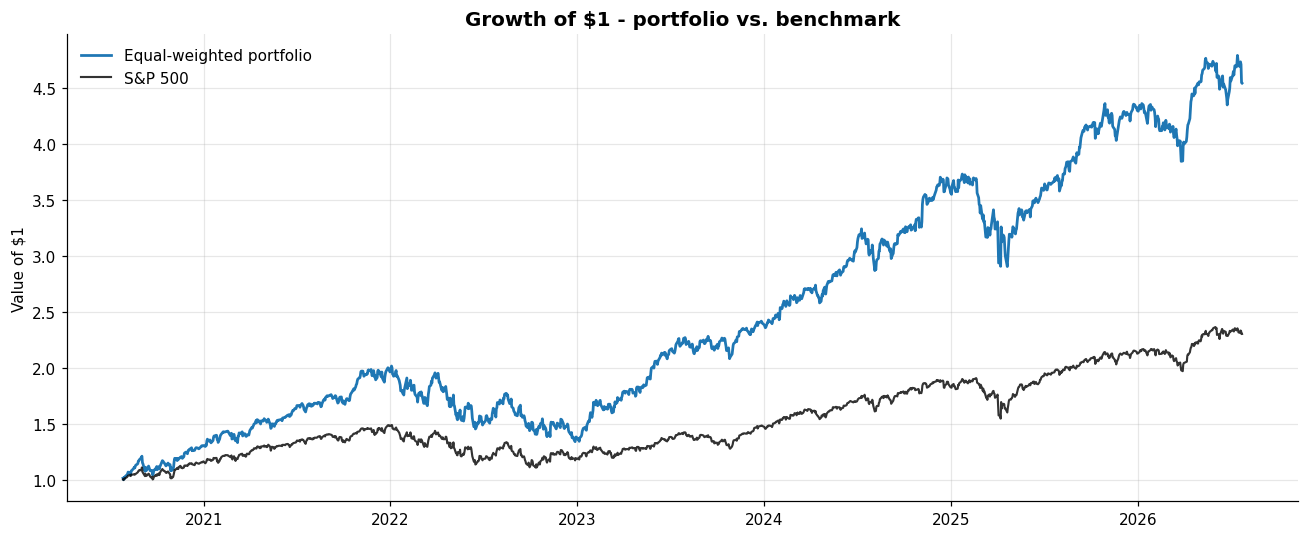

In [12]:
weights = pd.Series(1 / len(TICKERS), index=TICKERS)
port_simple = simple_ret.mul(weights, axis=1).sum(axis=1).rename('Portfolio')
port_log    = np.log1p(port_simple).rename('Portfolio')
shortcut    = log_ret.mul(weights, axis=1).sum(axis=1)

growth_correct  = np.exp(port_log.cumsum()).iloc[-1]
growth_shortcut = np.exp(shortcut.cumsum()).iloc[-1]
print(f'Growth of $1 (correct aggregation) : {growth_correct:.3f}')
print(f'Growth of $1 (avg of log returns)  : {growth_shortcut:.3f}')
print(f'Shortcut error over the sample     : {100*(growth_correct/growth_shortcut-1):.1f}%')
print('(Daily-rebalanced equal weight; Task 3 models realistic monthly rebalancing.)')

bench_log = bench_log.reindex(port_log.index)
fig, ax = plt.subplots()
ax.plot(np.exp(port_log.cumsum()), label='Equal-weighted portfolio', lw=1.8)
ax.plot(np.exp(bench_log.cumsum()), label='S&P 500', color='black', lw=1.4, alpha=0.8)
ax.set_title('Growth of $1 - portfolio vs. benchmark'); ax.set_ylabel('Value of $1'); ax.legend()
plt.tight_layout(); plt.show()

## 7. Volatility: rolling vs. EWMA
- **21-day rolling**: about one trading month. It reacts quickly but is noisy.
- **63-day rolling**: about one quarter. Smoother, but it lags.
- **EWMA (RiskMetrics)**: $\sigma_t^2 = \lambda\sigma_{t-1}^2 + (1-\lambda)r_{t-1}^2$, with λ = 0.94. Recent days get more weight, which is the industry standard for parametric VaR.

All three are annualised with √252.

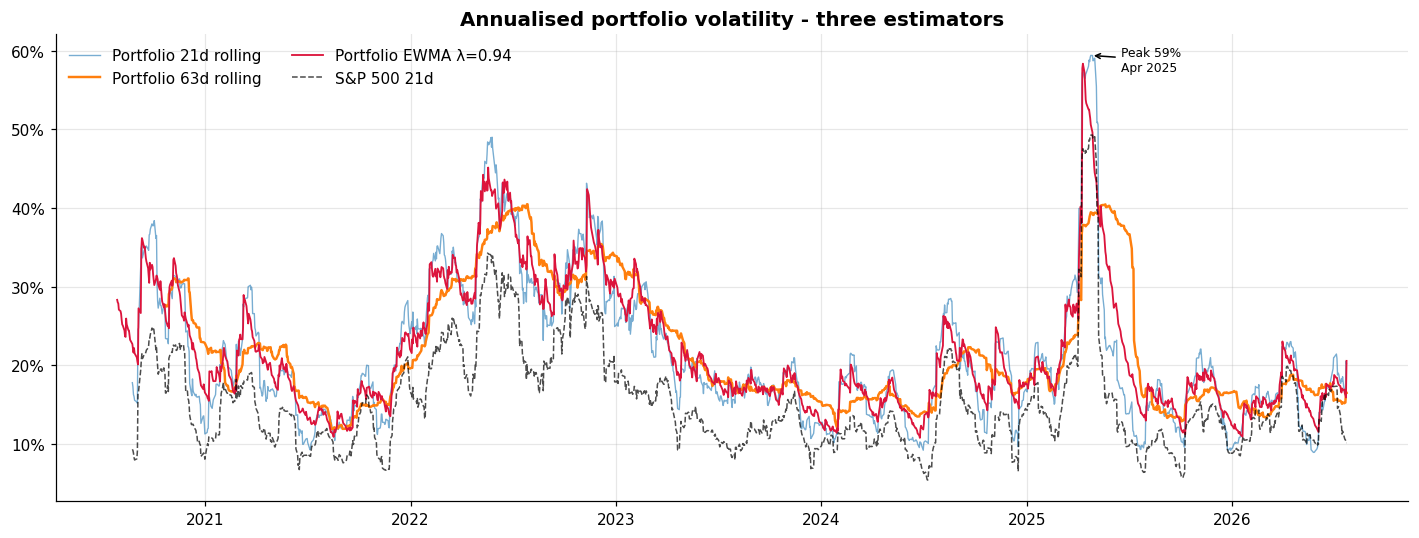

,Rolling 21d,Rolling 63d,EWMA (0.94),S&P 500 21d
mean,21.3%,21.8%,21.8%,15.4%
min,8.9%,11.8%,10.8%,5.4%
max,59.4%,40.5%,58.4%,49.3%


In [13]:
ann = np.sqrt(TRADING_DAYS)
vol = pd.DataFrame({
    'Rolling 21d': port_log.rolling(21).std() * ann,
    'Rolling 63d': port_log.rolling(63).std() * ann,
    'EWMA (0.94)': np.sqrt((port_log**2).ewm(alpha=1 - EWMA_LAMBDA, adjust=False).mean().shift(1)) * ann,
    'S&P 500 21d': bench_log.rolling(21).std() * ann,
})

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(vol['Rolling 21d'], lw=0.9, alpha=0.6, label='Portfolio 21d rolling')
ax.plot(vol['Rolling 63d'], lw=1.6, label='Portfolio 63d rolling')
ax.plot(vol['EWMA (0.94)'], lw=1.2, color='crimson', label='Portfolio EWMA λ=0.94')
ax.plot(vol['S&P 500 21d'], lw=1, color='black', ls='--', alpha=0.7, label='S&P 500 21d')
peak = vol['Rolling 21d'].idxmax()
ax.annotate(f'Peak {vol["Rolling 21d"].max():.0%}\n{peak:%b %Y}', (peak, vol['Rolling 21d'].max()),
            xytext=(20, -10), textcoords='offset points', arrowprops=dict(arrowstyle='->'), fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('Annualised portfolio volatility - three estimators'); ax.legend(ncol=2)
plt.tight_layout(); plt.show()
vol.describe().loc[['mean', 'min', 'max']].style.format('{:.1%}')

## 8. Distribution diagnostics
VaR models usually assume normal returns. Here we test that assumption. Positive excess kurtosis means fat tails, so a normal VaR would underestimate extreme losses.

In [14]:
from scipy import stats
panel = log_ret.join(port_log).join(bench_log.rename('S&P 500'))
def describe(s):
    s = s.dropna()
    jb = stats.jarque_bera(s)
    return pd.Series({
        'Ann. return': s.mean() * TRADING_DAYS, 'Ann. vol': s.std() * ann,
        'Skew': s.skew(), 'Excess kurtosis': s.kurt(),
        'Worst day': s.min(), 'Best day': s.max(),
        'JB p-value': jb.pvalue, 'Normal?': 'Yes' if jb.pvalue > 0.05 else 'No',
    })
diag = panel.apply(describe).T
diag.style.format({'Ann. return': '{:.1%}', 'Ann. vol': '{:.1%}', 'Skew': '{:.2f}', 'Excess kurtosis': '{:.2f}',
                   'Worst day': '{:.1%}', 'Best day': '{:.1%}', 'JB p-value': '{:.1e}'}) \
          .background_gradient(subset=['Ann. vol', 'Excess kurtosis'], cmap='Reds')

,Ann. return,Ann. vol,Skew,Excess kurtosis,Worst day,Best day,JB p-value,Normal?
AAPL,22.0%,28.9%,0.18,4.89,-9.7%,14.3%,0.0e+00,No
MSFT,11.6%,26.8%,-0.12,3.22,-10.5%,9.7%,1.9e-141,No
NVDA,50.4%,50.1%,0.19,3.62,-18.6%,21.8%,1.1e-179,No
GOOGL,24.3%,31.0%,-0.01,3.09,-10.0%,9.7%,1.4e-129,No
META,16.0%,43.4%,-0.99,23.30,-30.6%,20.9%,0.0e+00,No
AMZN,7.3%,34.7%,-0.09,4.58,-15.1%,12.7%,3.5e-285,No
TSLA,20.0%,61.0%,-0.06,3.18,-23.7%,20.4%,3.0e-137,No
JPM,24.0%,25.0%,0.31,6.03,-7.8%,12.7%,0.0e+00,No
XOM,25.8%,28.5%,0.04,2.16,-8.2%,11.9%,5.1e-64,No
UNH,7.3%,31.4%,-2.86,36.59,-25.3%,11.3%,0.0e+00,No


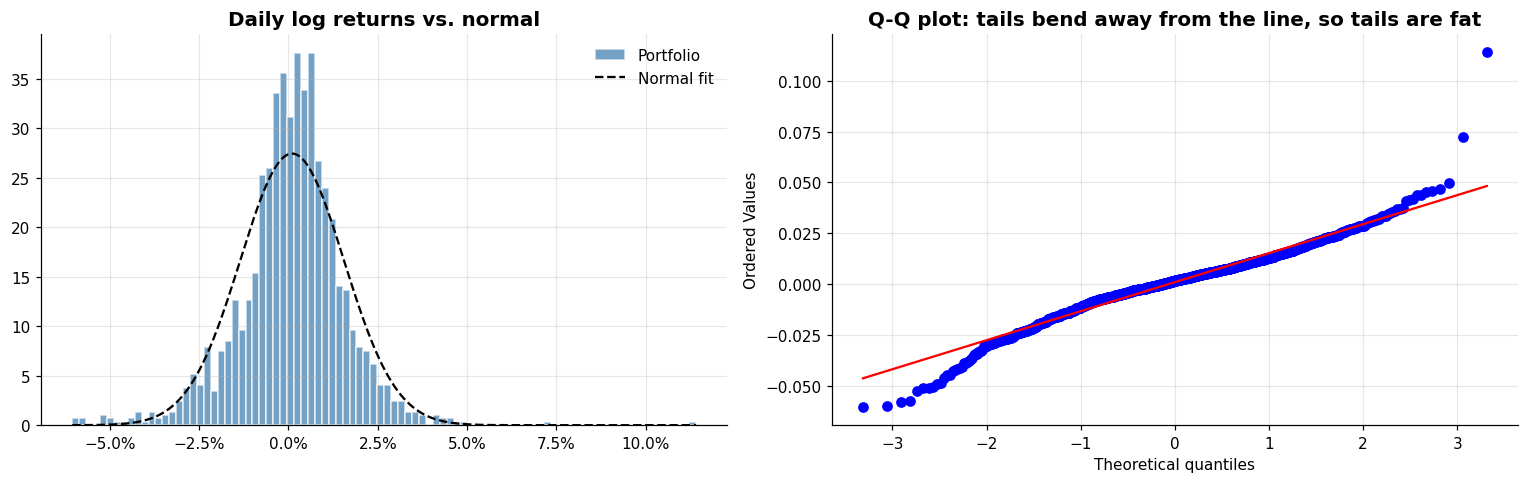

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = port_log.dropna()
axes[0].hist(x, bins=90, density=True, color='steelblue', alpha=0.75, edgecolor='white', label='Portfolio')
grid = np.linspace(x.min(), x.max(), 400)
axes[0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), 'k--', label='Normal fit')
axes[0].set_title('Daily log returns vs. normal'); axes[0].legend()
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
stats.probplot(x, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot: tails bend away from the line, so tails are fat')
plt.tight_layout(); plt.show()

### Correlation structure
Higher correlation means less diversification. Tech and communication names cluster together, while XOM, UNH and JPM are the diversifiers.

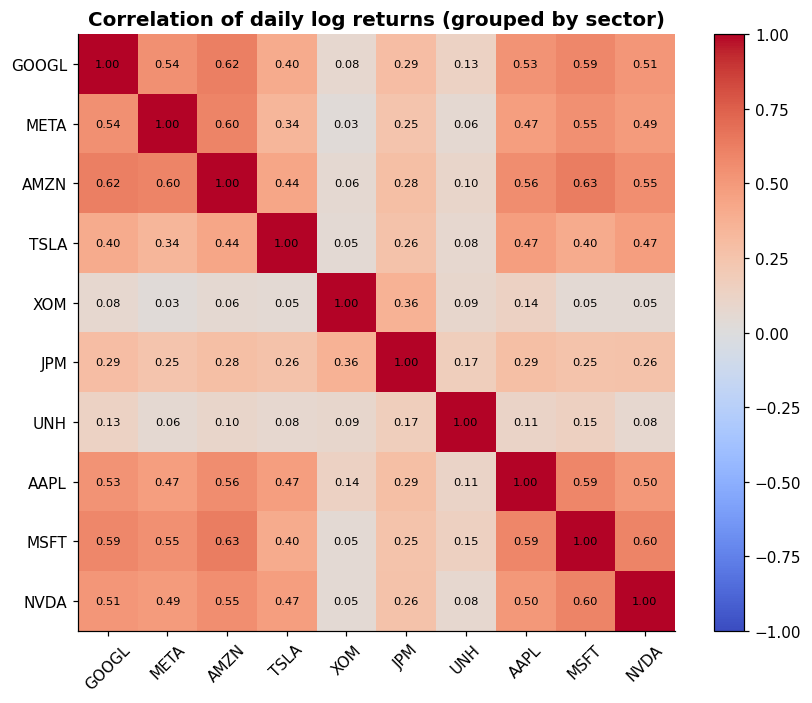

Average pairwise correlation: 0.32  (min 0.03, max 0.63)


In [16]:
corr = log_ret.corr()
order = sorted(TICKERS, key=lambda t: UNIVERSE[t])
corr = corr.loc[order, order]
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=45); ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7.5)
ax.grid(False); ax.set_title('Correlation of daily log returns (grouped by sector)')
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
off = corr.values[np.triu_indices(len(order), 1)]
print(f'Average pairwise correlation: {off.mean():.2f}  (min {off.min():.2f}, max {off.max():.2f})')

## 9. Save clean outputs + audit log

In [17]:
prices_clean.to_csv('Clean_Price_Matrix.csv')
log_ret.to_csv('Clean_Return_Matrix.csv')                 # log returns (matches project spec)
simple_ret.to_csv('Clean_Simple_Return_Matrix.csv')
pd.DataFrame({'Portfolio_LogReturn': port_log, 'Portfolio_SimpleReturn': port_simple}).to_csv('Portfolio_Returns.csv')
pd.DataFrame({'Benchmark_LogReturn': bench_log}).to_csv('Benchmark_Returns.csv')
vol.to_csv('Rolling_Volatility.csv')
diag.to_csv('Return_Diagnostics.csv')
audit_df = pd.DataFrame(audit)
audit_df.to_csv('Cleaning_Audit_Log.csv', index=False)
print('Saved: Clean_Price_Matrix, Clean_Return_Matrix, Clean_Simple_Return_Matrix, Portfolio_Returns,\n'
      '       Benchmark_Returns, Rolling_Volatility, Return_Diagnostics, Cleaning_Audit_Log (.csv)')
audit_df

Saved: Clean_Price_Matrix, Clean_Return_Matrix, Clean_Simple_Return_Matrix, Portfolio_Returns,
       Benchmark_Returns, Rolling_Volatility, Return_Diagnostics, Cleaning_Audit_Log (.csv)


,Step,Detail,Observations affected
0,Calendar,Duplicate dates removed,0
1,Calendar,Stock dates not on benchmark calendar dropped,0
2,Missing,Gaps forward-filled (limit 3 days),0
3,Missing,Rows dropped with remaining NaNs (leading / lo...,0
4,Stale,Stale runs of >= 5 days found,0
5,Outliers,Returns with |robust z| > 8.0,15
6,Outliers,All flagged moves are genuine - tails preserve...,0


## Key takeaways
- The data is aligned to the benchmark calendar, gap-filled with a strict limit, and checked for stale feeds and bad ticks, with every action recorded in the audit log.
- **Tails are kept on purpose.** The comparison table shows that blanket winsorizing would make VaR look smaller than it is.
- Portfolio returns are aggregated from simple returns, which avoids the error from averaging log returns.
- Returns are clearly **not normal** (fat tails, negative skew), which is evidence for historical and EWMA VaR over plain normal VaR in the later phases.
- EWMA volatility reacts to stress much faster than a 63-day window does.

**Next → Task 3: Portfolio Construction** (rebalancing engine, value, P&L, risk metrics).

*Prepared by Arham Shah.*